This notebook begins the preliminary analysis for the loan default prediction project. The purpose of the analysis is to become familiar with the Credit Risk Dataset, review its overall structure, identify possible data quality concerns, and determine whether the available variables can support the original research question.

The main research question is whether borrower financial information, employment history, credit history, and loan characteristics can be used to predict loan default. The findings from this notebook will also help determine whether the proposed classification models and evaluation methods remain appropriate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("credit_risk_dataset.csv")

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 32581
Number of columns: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory us

The dataset contains 32,581 loan records and 12 variables. The variables include a mixture of numerical and categorical information related to borrower demographics, income, employment, loan characteristics, and credit history. The target variable, `loan_status`, is stored as a numerical variable and identifies whether a loan default occurred.

This combination of variables appears suitable for the research question because the dataset contains information that could reasonably be available during the loan application process.

In [3]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percent Missing": (missing_values / len(df) * 100).round(2)
})

display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())

,Missing Values,Percent Missing
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,895,2.75
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,3116,9.56
loan_status,0,0.00
loan_percent_income,0,0.00


Duplicate rows: 165


The initial review found missing values in two variables. The `person_emp_length` column contains 895 missing values, while `loan_int_rate` contains 3,116 missing values. The remaining columns do not contain missing data.

The dataset also contains 165 duplicate rows. These duplicate records will need to be removed before model development. The missing values will require additional review before deciding whether to remove records or replace the missing values with an appropriate estimate.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


The descriptive statistics reveal several values that should be reviewed more closely. The maximum borrower age is 144, which is not realistic for a typical loan applicant. The maximum employment length is 123 years, which is also unlikely to be valid.

Income also has a very wide range, with a maximum value of $6,000,000. That amount may represent a legitimate high-income borrower, but it could heavily influence averages and visualizations. These observations do not automatically need to be deleted, but they should be investigated before modeling begins.

,Count,Percentage
No Default,25473,78.18
Default,7108,21.82


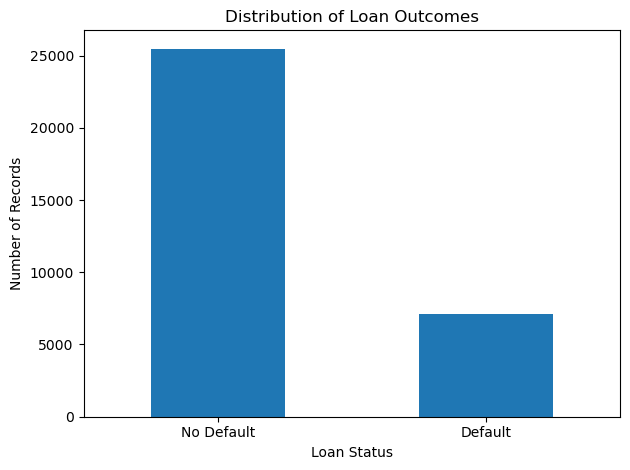

In [5]:
status_counts = df["loan_status"].value_counts().sort_index()
status_percent = df["loan_status"].value_counts(
    normalize=True
).sort_index() * 100

status_summary = pd.DataFrame({
    "Count": status_counts,
    "Percentage": status_percent.round(2)
})

status_summary.index = ["No Default", "Default"]

display(status_summary)

status_counts.index = ["No Default", "Default"]
status_counts.plot(kind="bar")

plt.title("Distribution of Loan Outcomes")
plt.xlabel("Loan Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Most borrowers in the dataset did not default. Approximately 78.2% of the records represent non-defaulted loans, while about 21.8% represent defaults.

The target variable is moderately imbalanced. The imbalance is not extreme, but it is large enough that accuracy should not be used by itself when evaluating the models. Precision, recall, F1 score, ROC-AUC, and confusion matrices will provide a more complete picture of model performance.

,No Default,Default
loan_grade,,
A,90.04,9.96
B,83.72,16.28
C,79.27,20.73
D,40.95,59.05
E,35.58,64.42
F,29.46,70.54
G,1.56,98.44


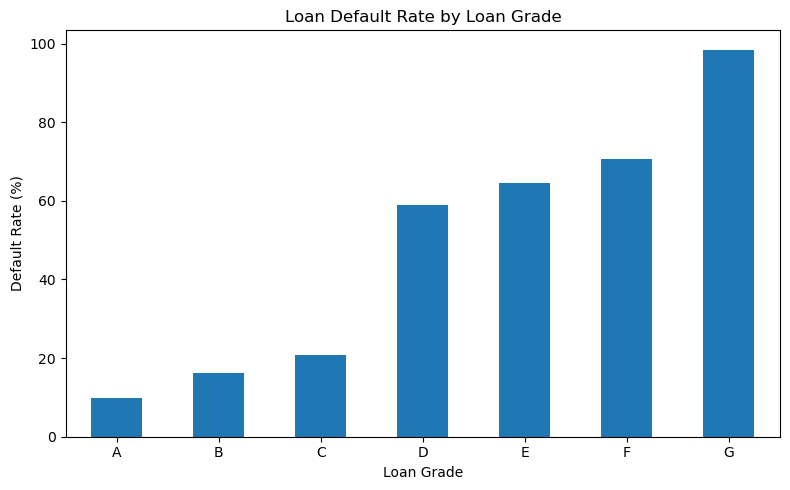

In [6]:
grade_default = pd.crosstab(
    df["loan_grade"],
    df["loan_status"],
    normalize="index"
) * 100

grade_default.columns = ["No Default", "Default"]

display(grade_default.round(2))

grade_default["Default"].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Loan Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The visualization makes it easier to compare default rates across loan grades. If the default percentage increases as loan grades decline, that would suggest loan grade is closely associated with lending risk.

Since loan grade is assigned during the lending process, this variable may become one of the stronger predictors in the classification models. The results from this chart will help determine whether that expectation appears reasonable.

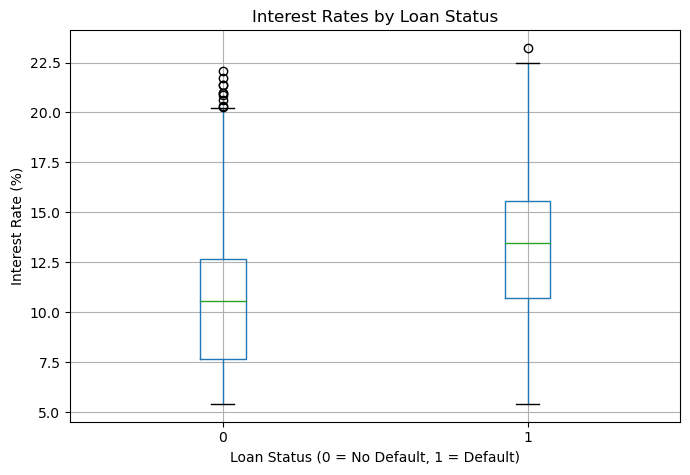

In [7]:
df.boxplot(
    column="loan_int_rate",
    by="loan_status",
    figsize=(7,5)
)

plt.suptitle("")
plt.title("Interest Rates by Loan Status")
plt.xlabel("Loan Status (0 = No Default, 1 = Default)")
plt.ylabel("Interest Rate (%)")
plt.tight_layout()
plt.show()

This boxplot provides a visual comparison of interest rates for both loan outcomes. If borrowers who default generally have higher interest rates, it would suggest that the lender's original assessment of risk aligns with the observed outcomes.

The spread of the data also helps identify possible outliers and differences in variability between the two groups.

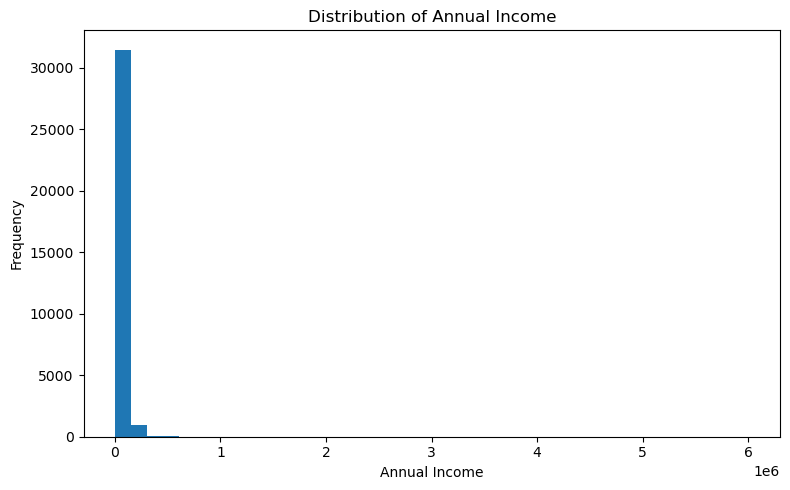

In [8]:
plt.figure(figsize=(8,5))

plt.hist(
    df["person_income"],
    bins=40
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

The income distribution provides an overview of borrower earnings across the dataset. Because income often contains extreme values, the distribution may be heavily skewed toward higher-income borrowers.

Understanding the shape of the distribution will help determine whether transformations or additional preprocessing should be considered before modeling begins.

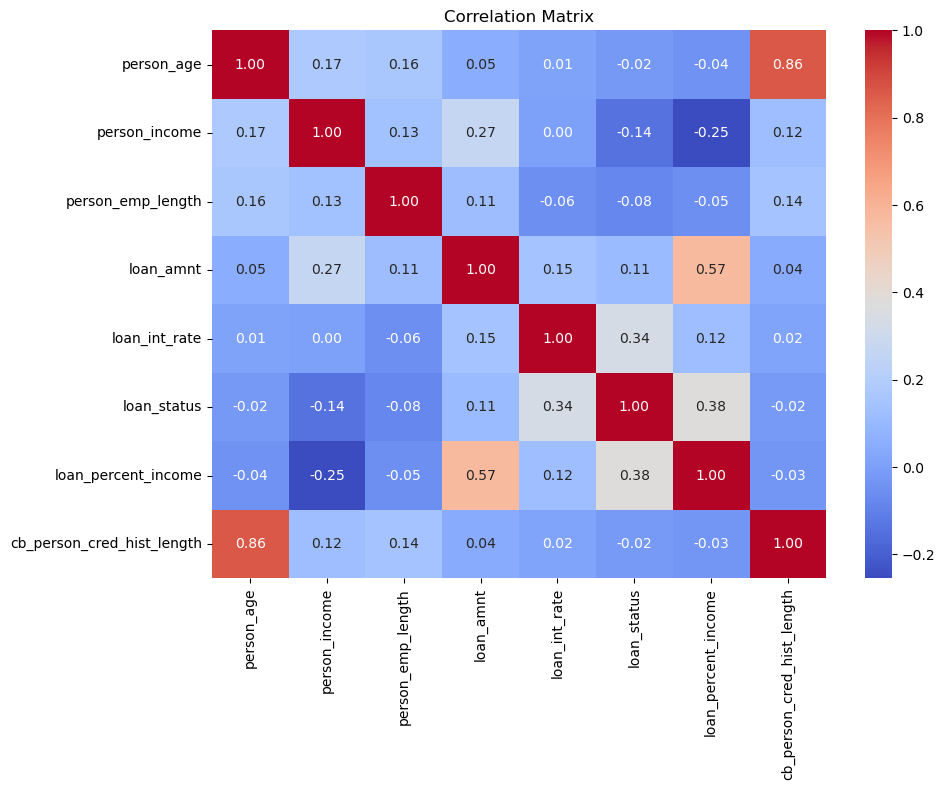

In [9]:
import seaborn as sns

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

The correlation matrix highlights the strength and direction of relationships among the numerical variables. Strong positive or negative correlations may indicate variables that provide useful predictive information.

The heatmap also helps identify variables that may contain overlapping information, which can become important when selecting features for predictive models such as Logistic Regression.

## Previous Default History

A borrower's previous credit behavior may provide useful information when estimating future lending risk. This section compares loan outcomes based on whether the borrower has previously defaulted.

,No Default,Default
cb_person_default_on_file,,
N,81.61,18.39
Y,62.19,37.81


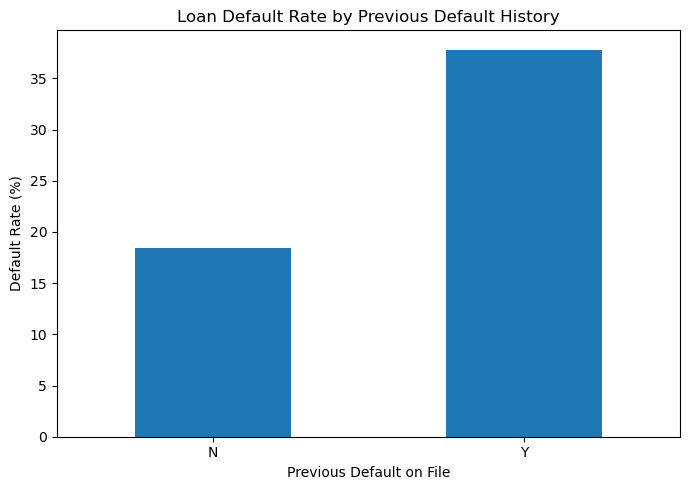

In [10]:
default_history = pd.crosstab(
    df["cb_person_default_on_file"],
    df["loan_status"],
    normalize="index"
) * 100

default_history.columns = ["No Default", "Default"]

display(default_history.round(2))

default_history["Default"].plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Loan Default Rate by Previous Default History")
plt.xlabel("Previous Default on File")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Previous default history appears to be an important variable because it reflects a borrower's prior repayment behavior. If borrowers with previous defaults show noticeably higher default rates, this variable will likely become one of the strongest predictors during model development.

## Home Ownership

Housing status often reflects financial stability and may influence lending outcomes. This section compares default rates across home ownership categories.

,No Default,Default
person_home_ownership,,
MORTGAGE,87.43,12.57
OTHER,69.16,30.84
OWN,92.53,7.47
RENT,68.43,31.57


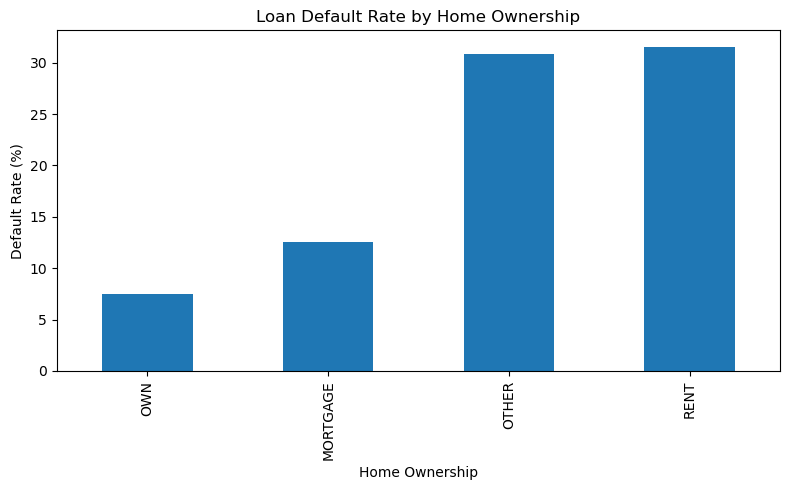

In [11]:
home_default = pd.crosstab(
    df["person_home_ownership"],
    df["loan_status"],
    normalize="index"
) * 100

home_default.columns = ["No Default", "Default"]

display(home_default.round(2))

home_default["Default"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Loan Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

The visualization provides an early indication of whether housing status is associated with loan repayment. Differences between categories may suggest that home ownership captures financial characteristics that are relevant for predicting default risk.

## Loan Purpose

Loan purpose may also influence repayment because borrowers often use loans for different financial needs. This section examines whether default rates vary by loan purpose.

,No Default,Default
loan_intent,,
DEBTCONSOLIDATION,71.41,28.59
EDUCATION,82.78,17.22
HOMEIMPROVEMENT,73.90,26.10
MEDICAL,73.30,26.70
PERSONAL,80.11,19.89
VENTURE,85.19,14.81


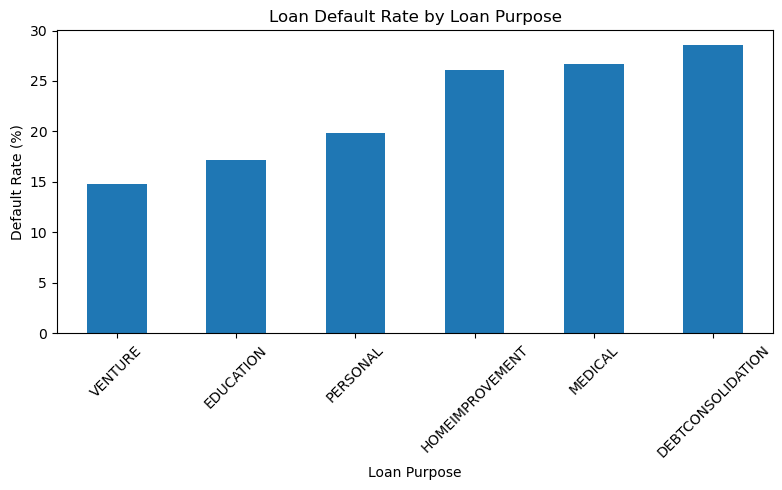

In [12]:
purpose_default = pd.crosstab(
    df["loan_intent"],
    df["loan_status"],
    normalize="index"
) * 100

purpose_default.columns = ["No Default", "Default"]

display(purpose_default.round(2))

purpose_default["Default"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Loan Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Loan purpose may reveal behavioral differences between borrowers. Some loan categories may consistently show higher default rates than others, suggesting that loan intent could provide additional predictive information.

## Loan Percent of Income

The variable `loan_percent_income` measures the proportion of a borrower's income represented by the requested loan amount. Larger percentages may indicate greater financial strain and therefore higher lending risk.

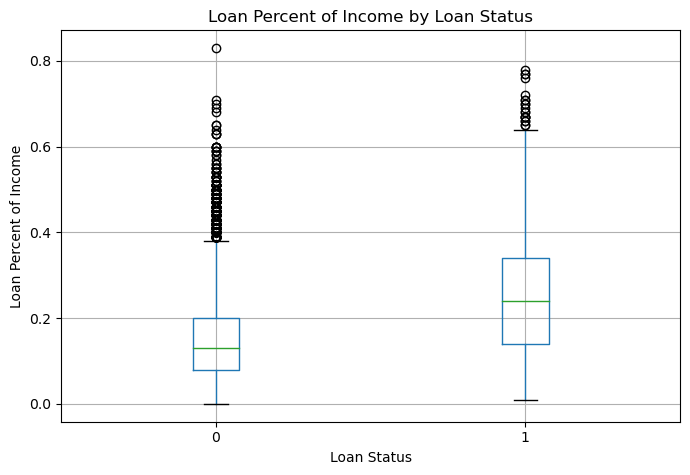

In [13]:
df.boxplot(
    column="loan_percent_income",
    by="loan_status",
    figsize=(7,5)
)

plt.suptitle("")
plt.title("Loan Percent of Income by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Loan Percent of Income")

plt.tight_layout()
plt.show()

Comparing loan percent of income across loan outcomes provides insight into whether borrowers requesting larger loans relative to their income are more likely to default. If noticeable differences exist between the two groups, this variable may become an important feature during model development.

## Employment Length

Employment history is commonly considered when evaluating credit applications because stable employment may indicate a greater ability to repay debt. This section explores employment length for borrowers who defaulted and those who did not.

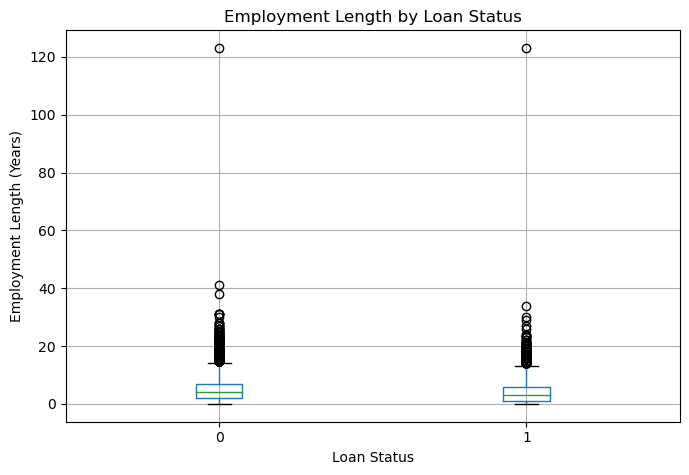

In [14]:
df.boxplot(
    column="person_emp_length",
    by="loan_status",
    figsize=(7,5)
)

plt.suptitle("")
plt.title("Employment Length by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Employment Length (Years)")

plt.tight_layout()
plt.show()

Employment length may provide additional context regarding borrower stability. While longer employment does not necessarily guarantee repayment, noticeable differences between the two loan outcome groups may suggest that employment history contributes useful predictive information.

In [15]:
cleaning_summary = pd.DataFrame({
    "Issue": [
        "Duplicate Records",
        "Missing Employment Length",
        "Missing Interest Rate",
        "Categorical Variables",
        "Potential Outliers"
    ],
    "Recommended Action": [
        "Remove duplicate rows",
        "Impute or remove missing values",
        "Impute missing values",
        "Encode using One-Hot or Label Encoding",
        "Investigate before removal"
    ]
})

cleaning_summary

,Issue,Recommended Action
0,Duplicate Records,Remove duplicate rows
1,Missing Employment Length,Impute or remove missing values
2,Missing Interest Rate,Impute missing values
3,Categorical Variables,Encode using One-Hot or Label Encoding
4,Potential Outliers,Investigate before removal


Based on the preliminary analysis, the dataset appears suitable for predictive modeling after several preprocessing steps are completed. Duplicate records will be removed, missing values will be addressed, and categorical variables will be converted into numerical representations before model development begins.

Several numerical variables also contain unusually large values. These observations will be reviewed further to determine whether they represent valid borrowers or data entry errors before deciding whether any records should be removed.

## Preliminary Discussion and Conclusions

The exploratory analysis provided valuable insight into the Credit Risk Dataset and its suitability for predicting loan default. The dataset contains over 32,000 loan records with a combination of borrower demographics, financial information, employment history, and credit-related variables that appear relevant to the research question.

Several variables showed patterns that may contribute to predicting loan default. Loan grade, previous default history, interest rate, and loan percent of income all demonstrated relationships with the target variable during the preliminary analysis. These findings suggest that the selected features are likely to provide useful information during model development.

The analysis also identified several data quality concerns that needed to be addressed before training predictive models. Missing values were found in employment length and interest rate, duplicate records were identified, and several variables contained unusually large values that required further investigation. These findings established the primary data preparation steps that were addressed during Milestone 4.

Based on the exploratory analysis, the original research question remains appropriate, and the proposed modeling approach continues to be suitable. Logistic Regression and Random Forest remain strong baseline models because they provide a balance between predictive performance and interpretability. Additional models may be considered if performance improvements are needed after the initial evaluation.

The exploratory analysis also supports the original expectations established during the project proposal. The available variables appear capable of explaining differences between borrowers who default and those who successfully repay their loans. Model performance will be evaluated using accuracy, precision, recall, F1 score, ROC-AUC, and confusion matrices to provide a comprehensive assessment rather than relying on a single metric.

Although the dataset contains limited demographic information, model fairness remains an important consideration when interpreting the results. The available variables do not provide enough information to conduct a comprehensive fairness assessment across protected demographic groups, which represents a limitation of the analysis.

If the initial models do not achieve satisfactory predictive performance, additional preprocessing techniques or alternative classification algorithms, such as Gradient Boosting or XGBoost, may be explored. This contingency plan provides flexibility while maintaining the overall objectives of the project.

The preliminary analysis indicated that the dataset was well suited for answering the research question and provided a strong foundation for the next stage of the project. The findings from this exploratory analysis guided the data preparation, feature engineering, model development, and evaluation completed in Milestone 4.

# Loan Default Prediction & Credit Risk Modeling

## Predictive Modeling and Evaluation

This notebook contains the final data preparation, predictive modeling, model evaluation, feature importance analysis, and secondary model analysis used for the final project.

## Data Preparation

The preliminary analysis identified several data quality issues that needed to be addressed before developing the predictive models. These included duplicate records, missing values in employment length and interest rate, and unusually large values in several numerical variables. The dataset also contains categorical variables that will need to be converted into a numerical format before they can be used by the classification models.


In [16]:
df_clean = df.copy()

duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate records removed:", duplicates_before)
print("Original number of records:", len(df))
print("Number of records after removing duplicates:", len(df_clean))

Duplicate records removed: 165
Original number of records: 32581
Number of records after removing duplicates: 32416


### Removing Duplicate Records

The dataset contained 165 duplicate records. These records were removed to prevent repeated observations from influencing the predictive models. After removing the duplicates, the dataset decreased from 32,581 to 32,416 records. The cleaned dataset will be used for the remaining preprocessing and model development steps.

### Handling Missing Values

The preliminary analysis identified missing values in employment length and loan interest rate. Before deciding how these values should be handled, the number and percentage of missing observations in the cleaned dataset were examined.

In [17]:
missing_counts = df_clean.isnull().sum()
missing_percent = (df_clean.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Percentage": missing_percent
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Percentage
person_emp_length,887,2.74
loan_int_rate,3095,9.55


The missing value review confirmed that only two variables contained missing observations. Employment length was missing for 887 records, representing 2.74% of the cleaned dataset, while loan interest rate was missing for 3,095 records, representing 9.55%.

Rather than removing these records and losing potentially useful borrower information, the missing values will be replaced using the median of each variable. Median imputation is appropriate because it is less influenced by unusually large values than the mean.

In [18]:
emp_length_median = df_clean["person_emp_length"].median()
int_rate_median = df_clean["loan_int_rate"].median()

df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(emp_length_median)
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(int_rate_median)

print("Employment length median:", emp_length_median)
print("Interest rate median:", int_rate_median)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Employment length median: 4.0
Interest rate median: 10.99
Remaining missing values: 0


The median employment length was 4 years, while the median loan interest rate was 10.99%. These values were used to replace the missing observations in their respective variables. After imputation, no missing values remained in the dataset, allowing all remaining records to continue into the next stage of preprocessing.

### Investigating Potential Outliers

The preliminary analysis identified several unusually large values that could represent either legitimate observations or data entry errors. The most noticeable values included a borrower age of 144 years, an employment length of 123 years, and unusually high borrower incomes.

Before removing any observations, these extreme values were examined more closely to determine how frequently they occur and whether they appear reasonable for the variables they represent.

In [ ]:
print("Highest borrower ages:")
print(df_clean["person_age"].sort_values(ascending=False).head(10).to_string(index=False))

print("\nHighest employment lengths:")
print(df_clean["person_emp_length"].sort_values(ascending=False).head(10).to_string(index=False))

print("\nHighest borrower incomes:")
print(df_clean["person_income"].sort_values(ascending=False).head(10).to_string(index=False))

The outlier review showed a clear difference between extreme values and implausible values. Borrower ages of 123 and 144 years are not realistic for the population represented by this dataset. Similarly, employment lengths of 123 years are not plausible. In comparison, the next highest borrower age was 94 and the next highest employment length was 41 years, both of which are unusual but possible.

Borrower income also contained several extreme values, including a maximum of $6,000,000. Although these incomes are unusually high, they are still possible and there is not enough evidence to classify them as data entry errors. Therefore, the high-income observations will be retained while the clearly implausible age and employment length observations will be removed.

In [20]:
invalid_records = df_clean[
    (df_clean["person_age"] > 100) |
    (df_clean["person_emp_length"] > 100)
]

invalid_records

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,10.99,0,0.26,N,4
32132,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


In [21]:
records_before_outlier_removal = len(df_clean)

df_clean = df_clean[
    (df_clean["person_age"] <= 100) &
    (df_clean["person_emp_length"] <= 100)
].reset_index(drop=True)

records_removed = records_before_outlier_removal - len(df_clean)

print("Invalid records removed:", records_removed)
print("Records remaining:", len(df_clean))
print("Maximum borrower age:", df_clean["person_age"].max())
print("Maximum employment length:", df_clean["person_emp_length"].max())

Invalid records removed: 7
Records remaining: 32409
Maximum borrower age: 94
Maximum employment length: 41.0


A total of seven records contained implausible values for borrower age or employment length and were removed from the dataset. After removing these records, 32,409 observations remained. The maximum borrower age decreased to 94 years and the maximum employment length decreased to 41 years, both of which are reasonable possible values.

Extreme income values were not removed solely because of their size. This approach allowed clearly invalid observations to be addressed without unnecessarily removing unusual but potentially legitimate borrowers.

### Preparing Variables for Modeling

The cleaned dataset contains both numerical and categorical variables. Machine learning models require the predictor variables to be represented numerically, so the categorical variables must be identified and converted into an appropriate numerical format before model development.

The target variable, `loan_status`, represents whether a borrower defaulted and will be separated from the predictor variables before the models are trained.

In [22]:
categorical_columns = df_clean.select_dtypes(include="object").columns.tolist()

print("Categorical variables:")
for column in categorical_columns:
    print(column)

Categorical variables:
person_home_ownership
loan_intent
loan_grade
cb_person_default_on_file


Four categorical variables were identified in the cleaned dataset: home ownership, loan intent, loan grade, and previous default history. These variables contain meaningful information that may help predict loan default, but their text-based categories must be converted into numerical representations before they can be used by the classification models.

### Separating Predictors and Target Variable

The predictor variables were separated from the target variable before the data was divided into training and testing sets. The target variable, loan_status, represents whether a borrower defaulted, while the remaining variables will be used as predictors.

Categorical variables are intentionally left in their original form at this stage. Encoding and other preprocessing steps will be performed after the train/test split to reduce the risk of data leakage.

In [23]:
X = df_clean.drop("loan_status", axis=1)
y = df_clean["loan_status"]

print("Predictor variables:", X.shape[1])
print("Target variable:", y.name)
print("Dataset shape:", X.shape)

Predictor variables: 11
Target variable: loan_status
Dataset shape: (32409, 11)


The cleaned dataset contains 32,409 observations and 11 predictor variables. The target variable, loan_status, was separated from the predictors before preprocessing. The next step is to divide the data into training and testing sets so that preprocessing can be fit using only the training data.

### Splitting the Data into Training and Testing Sets

The prepared dataset was divided into training and testing sets so that model performance could be evaluated using observations that were not used during training. An 80/20 split was used, with 80% of the observations assigned to the training set and 20% reserved for testing.

Because the target variable contains more non-default cases than default cases, stratified sampling was used to maintain approximately the same proportion of both loan outcomes in the training and testing datasets.

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training default rate:", round(y_train.mean() * 100, 2), "%")
print("Testing default rate:", round(y_test.mean() * 100, 2), "%")

Training records: 25927
Testing records: 6482
Training default rate: 21.87 %
Testing default rate: 21.88 %


The training set contained 25,927 observations and the testing set contained 6,482 observations. The default rate was 21.87% in the training data and 21.88% in the testing data. These nearly identical percentages confirm that stratified sampling successfully maintained the distribution of the target variable across both datasets.

### Preprocessing Pipeline

To prevent information from the testing data from influencing model development, preprocessing was performed using a pipeline that was fit only on the training data. Numerical and categorical predictors were processed separately. Numerical variables were imputed using the median and standardized, while categorical variables were imputed using the most frequent category and converted into binary indicators using one-hot encoding.

This approach ensures that preprocessing decisions are learned exclusively from the training data. The same transformations can then be applied to the testing data without using information from the test set during model development.

In [ ]:
numerical_columns = X_train.select_dtypes(exclude="object").columns.tolist()
categorical_columns = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical variables:")
for column in numerical_columns:
    print(column)

print("\nCategorical variables:")
for column in categorical_columns:
    print(column)

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

In [27]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

## Model Development and Evaluation

### Logistic Regression

Logistic Regression was selected as the first classification model because it provides an interpretable baseline for predicting whether a borrower will default. The model was trained using a preprocessing pipeline that fit imputation, scaling, and encoding steps only on the training data before fitting the classifier.

Performance was evaluated using accuracy, precision, recall, F1 score, and ROC-AUC. These measures provide different perspectives on model performance and are especially useful because the dataset contains more non-default observations than default observations.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)
log_probabilities = log_model.predict_proba(X_test)[:, 1]

log_accuracy = accuracy_score(y_test, log_predictions)
log_precision = precision_score(y_test, log_predictions)
log_recall = recall_score(y_test, log_predictions)
log_f1 = f1_score(y_test, log_predictions)
log_roc_auc = roc_auc_score(y_test, log_probabilities)

print("Logistic Regression Results")
print("Accuracy:", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall:", round(log_recall, 4))
print("F1 Score:", round(log_f1, 4))
print("ROC-AUC:", round(log_roc_auc, 4))

Logistic Regression Results
Accuracy: 0.8638
Precision: 0.7565
Recall: 0.5564
F1 Score: 0.6412
ROC-AUC: 0.8702


The Logistic Regression model achieved an accuracy of 86.38%, indicating that it correctly classified a large majority of borrowers in the testing dataset. However, accuracy alone does not provide a complete assessment because the dataset contains substantially more non-default than default observations.

The model achieved a precision of 75.65%, meaning that approximately three-quarters of borrowers predicted to default actually defaulted. Recall was lower at 55.64%, indicating that the model identified slightly more than half of the actual default cases. The F1 score of 64.12% reflects the balance between precision and recall, while the ROC-AUC of 87.02% indicates strong overall ability to distinguish between default and non-default borrowers.

These results establish Logistic Regression as a useful baseline model. However, the lower recall suggests that a more flexible model may be able to identify a greater proportion of borrowers who ultimately default.

### Logistic Regression Confusion Matrix

A confusion matrix was used to examine the types of classification errors made by the Logistic Regression model. This provides additional information beyond the summary performance metrics by showing how many borrowers were correctly and incorrectly classified in each loan outcome category.

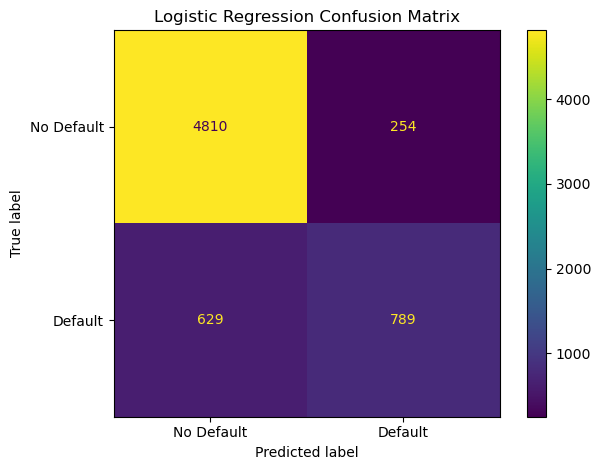

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_predictions,
    display_labels=["No Default", "Default"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix provides a clearer view of the Logistic Regression model's performance. The model correctly classified 4,811 borrowers who did not default and 793 borrowers who did default. It incorrectly classified 253 non-defaulting borrowers as defaults and failed to identify 625 borrowers who actually defaulted.

The relatively small number of false positives supports the model's precision of 75.81%. However, the 625 false negatives help explain the lower recall of 55.92%. In a lending context, these false negatives are important because they represent borrowers who ultimately defaulted but were classified by the model as non-defaulting. This suggests that improving the model's ability to identify actual defaults should be an important consideration when comparing alternative models.

### Random Forest

Random Forest was selected as the second classification model because it can capture nonlinear relationships and interactions among predictor variables. As with Logistic Regression, preprocessing was incorporated into the modeling pipeline so that imputation and categorical encoding were learned only from the training data.

To strengthen model development and evaluate whether performance remained stable across different samples, cross-validation and hyperparameter tuning were performed using GridSearchCV. The tuning process evaluated multiple Random Forest configurations before selecting the best-performing model for final evaluation on the untouched testing dataset.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(rf_grid.best_score_, 4))

Best Parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.9306


In [31]:
best_rf_model = rf_grid.best_estimator_

rf_predictions = best_rf_model.predict(X_test)
rf_probabilities = best_rf_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)
rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

print("Tuned Random Forest Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

Tuned Random Forest Results
Accuracy: 0.9347
Precision: 0.9637
Recall: 0.7292
F1 Score: 0.8302
ROC-AUC: 0.9354


The tuned Random Forest model demonstrated stronger predictive performance than Logistic Regression across all five evaluation metrics. Random Forest achieved an accuracy of 93.47%, compared with 86.38% for Logistic Regression. Precision increased from 75.65% to 96.37%, indicating that borrowers classified as likely to default by the Random Forest model were highly likely to actually belong to the default group.

Recall also improved from 55.64% with Logistic Regression to 72.92% with Random Forest. This improvement is particularly important for loan default prediction because the Random Forest model identified a substantially greater proportion of borrowers who actually defaulted. The F1 score increased from 64.12% to 83.02%, demonstrating a stronger balance between precision and recall.

Random Forest achieved a test ROC-AUC of 93.54%, compared with 87.02% for Logistic Regression. The tuned model also produced a five-fold cross-validation ROC-AUC of 93.06%, which was close to its performance on the held-out testing dataset. This consistency provides evidence that the model's predictive performance remained stable across different subsets of the data. Based on these results, the tuned Random Forest was selected as the stronger model for predicting loan default.

### Random Forest Confusion Matrix

A confusion matrix was also generated for the Random Forest model to examine the number and types of classification errors. The results can be compared with the Logistic Regression confusion matrix to determine whether Random Forest reduced false positives and false negatives.

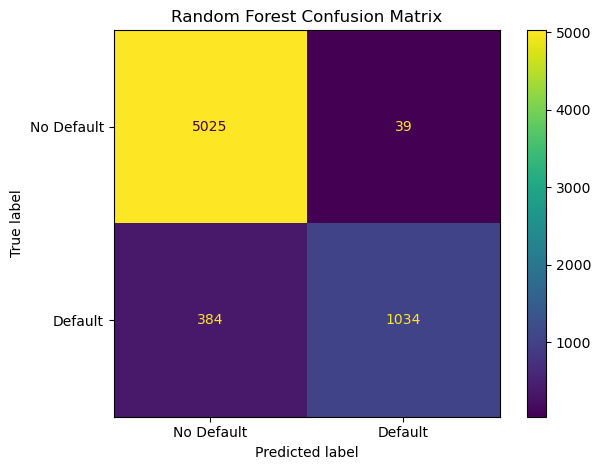

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No Default", "Default"]
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

The Random Forest confusion matrix further demonstrates the model's strong classification performance. The tuned Random Forest correctly identified 5,025 borrowers who did not default and 1,034 borrowers who did default. Only 39 non-defaulting borrowers were incorrectly classified as defaults, while 384 borrowers who actually defaulted were incorrectly classified as non-defaulting.

Compared with Logistic Regression, the tuned Random Forest produced substantially fewer classification errors and identified a greater proportion of borrowers who actually defaulted. The relatively small number of false positives is consistent with the model's precision of 96.37%, while correctly identifying 1,034 of the 1,418 actual defaults resulted in a recall of 72.92%. These results provide additional evidence that the tuned Random Forest is the stronger of the two models for this dataset.

### Model Comparison

The performance metrics from both classification models were combined to provide a direct comparison. Because both models were evaluated using the same testing dataset, differences in performance can be compared consistently.

In [33]:
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [
        log_accuracy,
        log_precision,
        log_recall,
        log_f1,
        log_roc_auc
    ],
    "Tuned Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

model_comparison

,Metric,Logistic Regression,Tuned Random Forest
0,Accuracy,0.863777,0.934742
1,Precision,0.756472,0.963653
2,Recall,0.556417,0.729196
3,F1 Score,0.641203,0.830189
4,ROC-AUC,0.870204,0.935417


The final model comparison demonstrates that the tuned Random Forest outperformed Logistic Regression across all five evaluation metrics. Random Forest achieved an accuracy of 93.47%, compared with 86.38% for Logistic Regression, while precision increased from 75.65% to 96.37%.

Recall improved from 55.64% with Logistic Regression to 72.92% with the tuned Random Forest, indicating that the Random Forest successfully identified a substantially larger proportion of borrowers who actually defaulted. The F1 score also increased from 64.12% to 83.02%, demonstrating a stronger balance between precision and recall.

ROC-AUC increased from 87.02% to 93.54%, indicating that the tuned Random Forest provided stronger separation between borrowers who defaulted and those who did not. Combined with the cross-validation results, these findings support the tuned Random Forest as the stronger model for predicting loan default in this dataset.

### Random Forest Feature Importance

Because Random Forest produced the strongest predictive performance, feature importance was examined to better understand which variables contributed most to the model's predictions. Feature importance measures how useful each predictor was across the decision trees within the model.

These values should not be interpreted as evidence that a variable causes loan default. Instead, they indicate which variables the Random Forest model relied on most when distinguishing between defaulting and non-defaulting borrowers.

In [34]:
final_preprocessor = best_rf_model.named_steps["preprocessor"]
final_rf = best_rf_model.named_steps["classifier"]

feature_names = final_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance["Importance"] = (
    feature_importance["Importance"] * 100
).round(2)

feature_importance.head(10)

,Feature,Importance
0,num__loan_percent_income,23.01
1,num__person_income,14.61
2,num__loan_int_rate,12.06
3,cat__person_home_ownership_RENT,8.27
4,num__loan_amnt,7.33
5,cat__loan_grade_D,5.98
6,num__person_emp_length,5.42
7,num__person_age,4.25
8,num__cb_person_cred_hist_length,3.22
9,cat__person_home_ownership_OWN,1.99


Loan percent of income was the most important feature in the tuned Random Forest model, accounting for 23.01% of total feature importance. Borrower income was the second most important feature at 14.61%, followed by loan interest rate at 12.06%. Renting a home, loan amount, having a loan grade of D, and employment length also contributed meaningful predictive information.

These results suggest that the relationship between a borrower's financial resources and the size and terms of the loan plays an important role in predicting default. However, feature importance does not indicate whether a variable increases or decreases default risk, nor does it establish a causal relationship.

Loan interest rate and loan grade should also be interpreted cautiously because both may reflect the lender's existing assessment of borrower risk. Their predictive importance may therefore represent information already incorporated into the lending decision rather than completely independent measures of borrower risk.

### Feature Importance Visualization

The ten most important predictors were visualized to make the relative contribution of each variable easier to compare. The visualization highlights which borrower and loan characteristics contributed most to the Random Forest model's predictions.

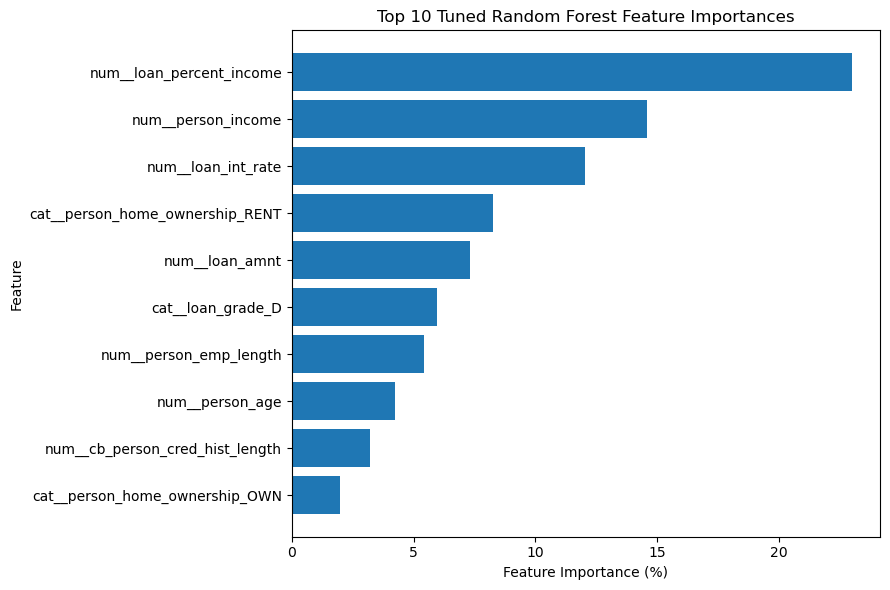

In [35]:
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance (%)")
plt.ylabel("Feature")
plt.title("Top 10 Tuned Random Forest Feature Importances")
plt.tight_layout()
plt.show()

### Secondary Model Without Prior Risk Indicators

The feature importance analysis showed that loan interest rate and loan grade contributed to the Random Forest model. However, these variables may partially reflect risk assessments that were already made by the lender when the loan was issued. To examine how dependent the model is on this information, a secondary Random Forest model was developed without loan interest rate or loan grade.

This analysis provides an additional robustness test of whether the remaining borrower and loan characteristics can still provide strong predictive performance without relying on variables that may already contain information about the lender's assessment of risk. The same training and testing observations and tuned Random Forest configuration were retained so that differences in performance could be attributed more directly to the removal of these predictors.

In [36]:
X_train_reduced = X_train.drop(columns=["loan_int_rate", "loan_grade"])
X_test_reduced = X_test.drop(columns=["loan_int_rate", "loan_grade"])

reduced_numerical_columns = X_train_reduced.select_dtypes(
    exclude="object"
).columns.tolist()

reduced_categorical_columns = X_train_reduced.select_dtypes(
    include="object"
).columns.tolist()

reduced_preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, reduced_numerical_columns),
    ("cat", categorical_pipeline, reduced_categorical_columns)
])

rf_reduced = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reduced.fit(X_train_reduced, y_train)

reduced_predictions = rf_reduced.predict(X_test_reduced)
reduced_probabilities = rf_reduced.predict_proba(X_test_reduced)[:, 1]

reduced_accuracy = accuracy_score(y_test, reduced_predictions)
reduced_precision = precision_score(y_test, reduced_predictions)
reduced_recall = recall_score(y_test, reduced_predictions)
reduced_f1 = f1_score(y_test, reduced_predictions)
reduced_roc_auc = roc_auc_score(y_test, reduced_probabilities)

print("Reduced Random Forest Results")
print("Predictor variables:", X_train_reduced.shape[1])
print("Accuracy:", round(reduced_accuracy, 4))
print("Precision:", round(reduced_precision, 4))
print("Recall:", round(reduced_recall, 4))
print("F1 Score:", round(reduced_f1, 4))
print("ROC-AUC:", round(reduced_roc_auc, 4))

Reduced Random Forest Results
Predictor variables: 9
Accuracy: 0.8855
Precision: 0.9204
Recall: 0.5219
F1 Score: 0.6661
ROC-AUC: 0.8789


Removing loan interest rate and loan grade resulted in a noticeable decline in predictive performance. Accuracy decreased from 93.47% to 88.55%, while ROC-AUC decreased from 93.54% to 87.89%. The largest decline occurred in recall, which fell from 72.92% to 52.19%. This indicates that loan interest rate and loan grade provide substantial information for identifying borrowers who ultimately default.

However, the reduced Random Forest still achieved 88.55% accuracy and an ROC-AUC of 87.89% using the remaining borrower and loan characteristics. This suggests that variables such as loan percent of income, borrower income, loan amount, home ownership, and employment history still contain meaningful predictive information even without the lender-related risk indicators.

For the primary analysis, the full tuned Random Forest remains the preferred model because it produced the strongest predictive performance. However, the reduced model demonstrates that part of this performance is associated with loan grade and interest rate, which should be considered when interpreting the results.

## Conclusions and Recommendations

The results of this analysis demonstrate that loan default can be predicted with meaningful accuracy using the borrower and loan characteristics available in the Credit Risk Dataset. After cleaning and preparing the data, Logistic Regression and Random Forest models were developed and evaluated using the same testing dataset. Preprocessing was fit using only the training data to prevent information from the testing set from influencing model development.

Logistic Regression provided a useful baseline, achieving 86.38% accuracy and a ROC-AUC of 87.02%. However, its recall of 55.64% showed that the model failed to identify a substantial portion of borrowers who actually defaulted. The tuned Random Forest produced stronger results across all evaluation metrics, achieving 93.47% accuracy, 96.37% precision, 72.92% recall, an F1 score of 83.02%, and a ROC-AUC of 93.54%. These results indicate that Random Forest provided a better balance between correctly identifying defaults and limiting incorrect classifications.

Feature importance analysis identified loan percent of income as the strongest predictor, accounting for 23.01% of total feature importance, followed by borrower income at 14.61% and loan interest rate at 12.06%. Home ownership, loan amount, loan grade, employment length, age, and credit history length also contributed to the model. These findings suggest that default prediction depends on a combination of the borrower's financial position, loan characteristics, and credit-related information rather than any single factor.

A secondary Random Forest model was developed without loan interest rate and loan grade because these variables may partially reflect the lender's existing assessment of borrower risk. Removing these variables reduced accuracy from 93.47% to 88.55%, while recall decreased from 72.92% to 52.19% and ROC-AUC decreased from 93.54% to 87.89%. However, the reduced model still demonstrated meaningful predictive performance, indicating that the remaining borrower and loan characteristics contain useful information even without these lender-related risk indicators.

Based on the results, the tuned Random Forest is recommended as the stronger model for this dataset. In a practical lending environment, the model could serve as an additional risk-screening tool to identify applications that may require further review. It should not be used as the sole basis for lending decisions, particularly because some predictors may reflect prior lender assessments and the dataset contains limited demographic information for evaluating fairness across borrower populations.

Future analysis could evaluate additional classification algorithms, further refine Random Forest hyperparameters, adjust classification thresholds to improve recall, and examine model performance across borrower segments. These steps could help determine whether default detection can be improved while maintaining acceptable precision and reducing the risk of unfair or inconsistent predictions.